# Forecasting US Electricity Prices

**How accurately can the average US price of electricity be forecast 1–12 months ahead, using price history alone?**

*An AI-assisted revision of my M.S. Data Analytics capstone (WGU, 2026), produced with Claude (Anthropic). The original, as submitted, is in [`D214-capstone-electricity-price-forecast/`](../../D214-capstone-electricity-price-forecast/). The section [Revisiting the original capstone](#Revisiting-the-original-capstone) lists what changed.*

## Summary

- **Data:** the monthly average US retail price of electricity (BLS, via [FRED series APU000072610](https://fred.stlouisfed.org/series/APU000072610)), March 2016 to March 2026.
- **Method:** I compared SARIMA, exponential smoothing (ETS) and three simple baselines in a **rolling-origin backtest**. From each of 25 starting points (quarterly, March 2019 to March 2025), every model forecasts the next 12 months, and its errors are averaged.
- **Result:** every method lands within a few percent. **SARIMA and ETS are the most accurate 1–3 months ahead, but at 12 months a straight-line trend (drift) forecast does as well or better.** Seasonality is weak, so most of the error comes from shifts in the price level, above all the 2021–22 surge.
- **The original capstone's headline result doesn't hold up.** It reported 0.77% MAPE on a single 30-month test window. Refitting the same model on the same data in cents instead of dollars gives 1.8%. Handling the missing month properly gives 2.4%, worse than the drift baseline.
- **Forecast:** an average of the drift, ETS and SARIMA forecasts puts prices at **about 19.6¢/kWh by March 2027**, up about 3% from 19.0¢ in March 2026 (80% interval: 19.1–21.8¢).

## 1. Why this matters

Electricity is an input to nearly everything. An OECD panel study estimates that a 10% rise in energy prices reduces GDP growth by about 0.15 percentage points, and by more in energy-intensive economies (Huntington & Liddle, 2022). Demand from data centers has put US retail prices back in the news (Bensaidani & Deveaux, 2026). Budgeting, procurement and household planning all depend on knowing how far ahead price history can usefully forecast prices, and how much error to expect.

In [1]:
import warnings
warnings.filterwarnings("ignore")  # statsmodels convergence chatter; fits are checked via the backtest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.precision", 2)

# Chart styling: neutral ink for history, a fixed categorical order for models
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
COLORS = {
    "Naive": "#2a78d6",
    "Seasonal naive": "#eb6834",
    "Drift": "#1baf7a",
    "ETS": "#eda100",
    "SARIMA": "#e87ba4",
    "Average (drift, ETS, SARIMA)": "#008300",
}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})

## 2. Data

The series is the Bureau of Labor Statistics' *average price of electricity per kilowatt-hour, U.S. city average*, collected for the CPI and republished on FRED. I downloaded it as a CSV covering March 2016 to March 2026. Two caveats: it's a national average of utility bills, so it isn't suitable for comparing places (BLS, 2026), and FRED's terms allow non-commercial use with attribution.

I work in **cents per kWh** for readability.

In [2]:
raw = pd.read_csv("data/APU000072610.csv", parse_dates=["observation_date"], index_col="observation_date")
price = (raw["APU000072610"] * 100).rename("cents_per_kwh").asfreq("MS")

print(f"{price.index.min():%b %Y} to {price.index.max():%b %Y}: {len(price)} months")
print("Missing months:", [f"{d:%b %Y}" for d in price[price.isna()].index])
print(price.loc["2025-08":"2025-12"])

Mar 2016 to Mar 2026: 121 months
Missing months: ['Oct 2025']
observation_date
2025-08-01    19.0
2025-09-01    18.8
2025-10-01     NaN
2025-11-01    18.9
2025-12-01    18.9
Freq: MS, Name: cents_per_kwh, dtype: float64


October 2025 is missing; BLS didn't publish it. The original capstone dropped the row, but that leaves a gap in a series the models treat as evenly spaced, and it shifts every later month by one position. Here the gap is filled by **linear interpolation** between September and November, which differ by only 0.1¢.

In [3]:
price = price.interpolate()
assert price.isna().sum() == 0 and pd.infer_freq(price.index) == "MS"
price.describe()

count    121.00
mean      15.22
std        1.95
min       13.10
25%       13.60
50%       14.20
75%       16.90
max       19.20
Name: cents_per_kwh, dtype: float64

## 3. What the series looks like

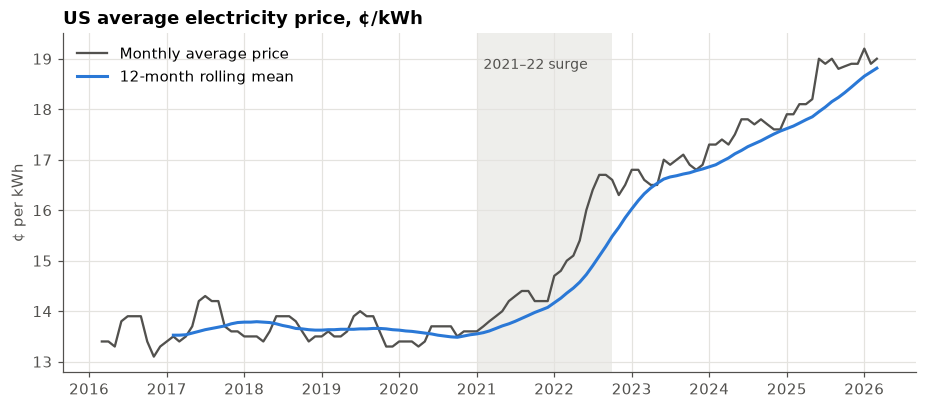

Year-over-year change in annual average price (%):
observation_date
2017-01-01     1.7
2018-01-01    -1.1
2019-01-01     0.1
2020-01-01    -0.7
2021-01-01     4.0
2022-01-01    12.6
2023-01-01     6.1
2024-01-01     4.5
2025-01-01     5.6
2026-01-01     2.6
Freq: YS-JAN


In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(pd.Timestamp("2021-01-01"), pd.Timestamp("2022-10-01"), color=GRID, alpha=0.6, lw=0)
ax.plot(price, color=INK_2, lw=1.5, label="Monthly average price")
ax.plot(price.rolling(12).mean(), color=COLORS["Naive"], label="12-month rolling mean")
ax.text(pd.Timestamp("2021-02-01"), 18.8, "2021–22 surge", color=INK_2, fontsize=9)
ax.set(title="US average electricity price, ¢/kWh", ylabel="¢ per kWh")
ax.legend(loc="upper left")
plt.show()

growth = price.resample("YS").mean().pct_change().mul(100).dropna()
print("Year-over-year change in annual average price (%):")
print(growth.round(1).to_string())

Prices were nearly flat from 2016 to 2020, at about 13–14¢, rose about 23% between early 2021 and late 2022 (13.6¢ to 16.7¢), and have kept climbing more slowly since. That shift in level is the hardest part to forecast: nothing in the series before 2021 predicts it.

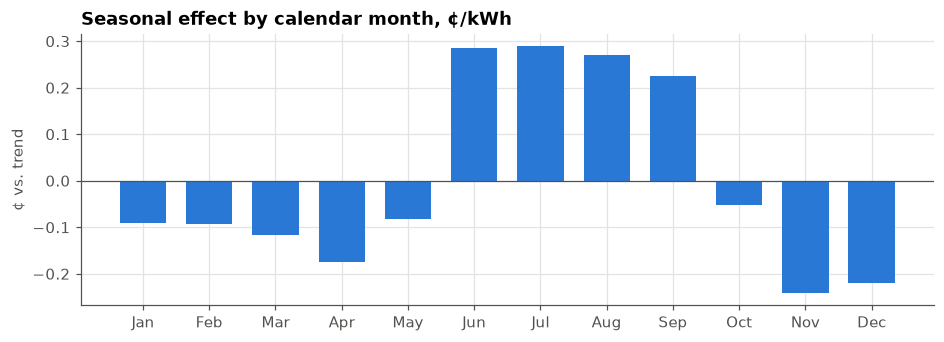

Peak-to-trough seasonal swing: 0.53¢, about 3.5% of the average price


In [5]:
decomp = seasonal_decompose(price, model="additive", period=12)
season = decomp.seasonal.groupby(decomp.seasonal.index.month).mean()
season.index = pd.to_datetime(season.index, format="%m").strftime("%b")

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(season.index, season.values, color=COLORS["Naive"], width=0.7)
ax.axhline(0, color=INK_2, lw=0.8)
ax.set(title="Seasonal effect by calendar month, ¢/kWh", ylabel="¢ vs. trend")
plt.show()

amp = season.max() - season.min()
print(f"Peak-to-trough seasonal swing: {amp:.2f}¢, about {amp / price.mean():.1%} of the average price")

There is a summer peak, but it's small: about 0.5¢, or roughly 3.5% of the average price from trough to peak. Changes in level matter far more than the seasonal pattern, which suggests a seasonal-naive forecast (repeat last year) will do badly and trend-following methods will do well.

## 4. Why one test window isn't enough

The original capstone fitted SARIMA(0,1,1)(0,1,2)₁₂ to all but the last 30 months, then scored a single 30-month forecast. The table repeats that setup three ways. The first row is the original exactly, in $/kWh with the missing month dropped. The second row is the same data in ¢/kWh. The third row is in ¢/kWh with the gap interpolated, which moves the split by one month. A drift forecast is included for comparison, and every SARIMA fit converged.

In [6]:
def mape(actual, forecast):
    actual, forecast = np.asarray(actual), np.asarray(forecast)
    return 100 * np.mean(np.abs(actual - forecast) / np.abs(actual))


def capstone_sarima(series, horizon):
    train, test = series.iloc[:-horizon], series.iloc[-horizon:]
    fit = SARIMAX(train, order=(0, 1, 1), seasonal_order=(0, 1, 2, 12), trend="c", freq="MS").fit(disp=False)
    return train, test, fit.forecast(horizon).values, fit.mle_retvals["converged"]


dollars_dropped = raw["APU000072610"].dropna()
setups = [("Original: $/kWh, missing month dropped", dollars_dropped),
          ("Same data in ¢/kWh", dollars_dropped * 100),
          ("¢/kWh, missing month interpolated", price)]
rows = []
for label, series in setups:
    train, test, fc, converged = capstone_sarima(series, 30)
    drift = train.iloc[-1] + (train.iloc[-1] - train.iloc[0]) / (len(train) - 1) * np.arange(1, 31)
    rows.append({"setup": label, "train ends": f"{train.index[-1]:%b %Y}",
                 "SARIMA MAPE %": mape(test, fc), "Drift MAPE %": mape(test, drift), "SARIMA converged": converged})
pd.DataFrame(rows).set_index("setup")

,train ends,SARIMA MAPE %,Drift MAPE %,SARIMA converged
setup,,,,
"Original: $/kWh, missing month dropped",Aug 2023,0.77,2.19,True
Same data in ¢/kWh,Aug 2023,1.78,2.19,True
"¢/kWh, missing month interpolated",Sep 2023,2.40,2.05,True


The same model on the same data scores 0.8% or 1.8% depending only on whether prices are recorded in dollars or cents. The likelihood is flat enough that the optimizer settles on different parameters, and the 30-month forecast amplifies the difference. With the missing month handled properly, SARIMA scores 2.4%, worse than a straight-line drift. A single test window tells you how one fit did on one window, not how good the method is. (The original also passed MAPE its arguments in the wrong order, `(forecast, actual)`. That changed the result only in the third decimal place, but it's fixed here.)

So the rest of this analysis uses a **rolling-origin backtest**: forecast from many starting points and average the errors.

## 5. Models and evaluation design

| Model | What it does |
|---|---|
| **Naive** | Repeats the last observed price. |
| **Seasonal naive** | Repeats the last 12 months. |
| **Drift** | Extends the average monthly change across the training history in a straight line. |
| **ETS** | Holt–Winters exponential smoothing with a damped additive trend and additive seasonality. |
| **SARIMA** | Seasonal ARIMA with D = 1 and m = 12 (as in the original capstone). `auto_arima` picks the order by AIC, re-selected at every forecast origin, so no future data leaks into model choice. |
| **Average** | The mean of the Drift, ETS and SARIMA forecasts. Averaging different methods is a robust default (Hyndman & Athanasopoulos, 2021). |

**Backtest:** 25 forecast origins, one per quarter from March 2019 to March 2025. At each origin, every model is refitted on all data up to that month and forecasts the next 12 months. The earliest origin has 37 months of training data, and the latest forecast ends in March 2026. Error is measured with **MAPE**, which is easy to read for a price series with no zeros, and with **MAE in cents**.

In [7]:
HORIZON = 12
ORIGINS = pd.date_range("2019-03-01", "2025-03-01", freq="3MS")


def drift_forecast(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)


def ets_forecast(train, h):
    model = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12)
    return model.fit().forecast(h).values


def sarima_forecast(train, h):
    model = auto_arima(train, m=12, D=1, with_intercept=True, suppress_warnings=True, error_action="ignore")
    return model.predict(h).values


MODELS = {
    "Naive": lambda tr, h: np.repeat(tr.iloc[-1], h),
    "Seasonal naive": lambda tr, h: np.resize(tr.iloc[-12:].values, h),
    "Drift": drift_forecast,
    "ETS": ets_forecast,
    "SARIMA": sarima_forecast,
}


def forecast_all(train, h):
    fc = {name: f(train, h) for name, f in MODELS.items()}
    fc["Average (drift, ETS, SARIMA)"] = np.mean([fc["Drift"], fc["ETS"], fc["SARIMA"]], axis=0)
    return fc


records = []
for origin in ORIGINS:
    train = price[:origin]
    actual = price[origin + pd.DateOffset(months=1):].iloc[:HORIZON]
    for name, fc in forecast_all(train, HORIZON).items():
        for h, (y, f) in enumerate(zip(actual.values, fc), start=1):
            records.append({"origin": origin, "model": name, "h": h, "actual": y, "forecast": f})

bt = pd.DataFrame(records)
bt["abs_err"] = (bt["actual"] - bt["forecast"]).abs()
bt["ape"] = 100 * bt["abs_err"] / bt["actual"]
print(f"{bt['origin'].nunique()} origins × {bt['model'].nunique()} models × {HORIZON} horizons = {len(bt):,} forecasts")

25 origins × 6 models × 12 horizons = 1,800 forecasts


## 6. Results

In [8]:
order = ["Average (drift, ETS, SARIMA)", "Drift", "ETS", "SARIMA", "Naive", "Seasonal naive"]
summary = pd.DataFrame({
    "MAPE %, 1–12 mo": bt.groupby("model")["ape"].mean(),
    "MAE ¢, 1–12 mo": bt.groupby("model")["abs_err"].mean(),
    **{f"MAPE % at {h} mo": bt[bt["h"] == h].groupby("model")["ape"].mean() for h in (1, 3, 6, 12)},
}).loc[order]
summary

,"MAPE %, 1–12 mo","MAE ¢, 1–12 mo",MAPE % at 1 mo,MAPE % at 3 mo,MAPE % at 6 mo,MAPE % at 12 mo
model,,,,,,
"Average (drift, ETS, SARIMA)",2.58,0.41,0.73,1.41,2.48,4.12
Drift,2.69,0.43,1.04,2.06,3.05,3.94
ETS,2.77,0.45,0.78,1.41,2.52,4.62
SARIMA,3.32,0.53,0.82,1.74,3.17,5.52
Naive,3.22,0.52,1.01,2.14,3.38,5.31
Seasonal naive,4.96,0.81,4.59,4.72,4.93,5.31


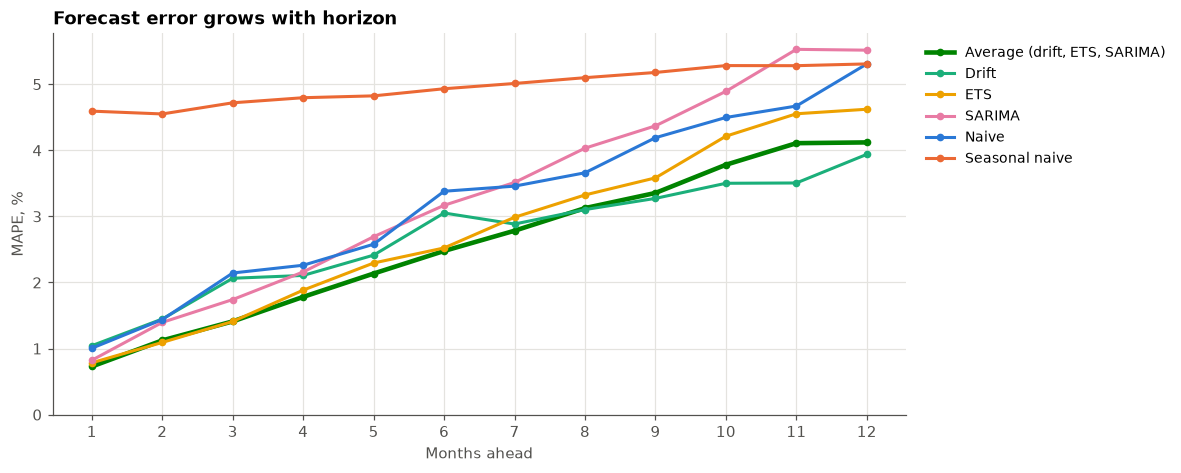

In [9]:
by_h = bt.groupby(["model", "h"])["ape"].mean().unstack("model")

fig, ax = plt.subplots(figsize=(10, 4.5))
for name in order:
    lw = 3 if name.startswith("Average") else 2
    ax.plot(by_h.index, by_h[name], color=COLORS[name], lw=lw, marker="o", ms=4, label=name)
ax.set(title="Forecast error grows with horizon", xlabel="Months ahead", ylabel="MAPE, %",
       xticks=range(1, 13), ylim=(0, None))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
plt.show()

- **1–3 months ahead,** the statistical models earn their keep: SARIMA, ETS and the average have errors of about 0.7–0.8% one month out, compared with about 1.0% for the naive and drift baselines.
- **By 12 months,** the order flips. Drift (3.9%) beats ETS (4.6%) and SARIMA (5.5%), and the average (4.1%) falls between them. The statistical models track recent movements closely, which helps for short horizons and hurts when the trend changes.
- **Seasonal naive is the worst at every horizon,** as the weak seasonality in section 3 predicted.
- Over the full 1–12 month range, the average (2.6%) and drift (2.7%) are essentially tied for best. **SARIMA, re-selected by `auto_arima` at each origin, is no better than the naive forecast overall (3.3% vs. 3.2%).**

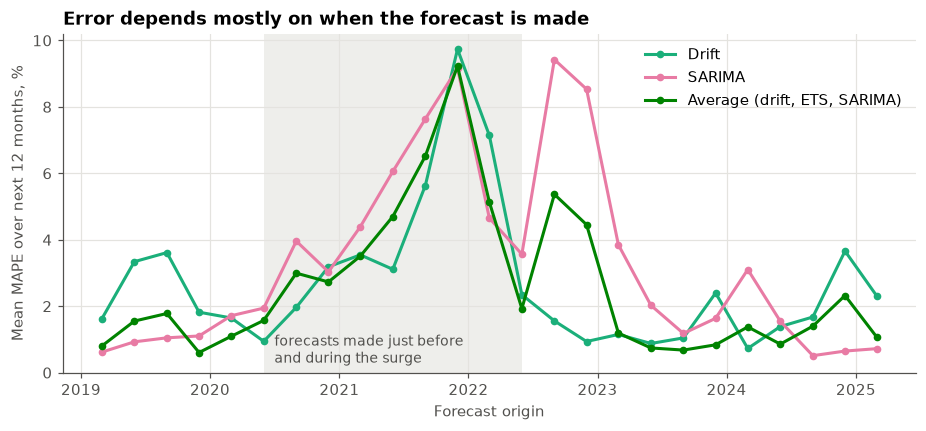

era,2019 – early 2020,mid-2020 – mid-2022,mid-2022 – 2025
model,,,
"Average (drift, ETS, SARIMA)",1.17,4.55,1.85
Drift,2.41,4.41,1.67
ETS,0.95,4.46,2.41
SARIMA,1.08,5.10,3.06
Naive,2.14,4.76,2.63
Seasonal naive,1.21,6.62,5.43


In [10]:
per_origin = bt.groupby(["origin", "model"])["ape"].mean().unstack("model")
show = ["Drift", "SARIMA", "Average (drift, ETS, SARIMA)"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.axvspan(pd.Timestamp("2020-06-01"), pd.Timestamp("2022-06-01"), color=GRID, alpha=0.6, lw=0)
for name in show:
    ax.plot(per_origin.index, per_origin[name], color=COLORS[name], marker="o", ms=4, label=name)
ax.text(pd.Timestamp("2020-07-01"), 0.3, "forecasts made just before\nand during the surge", color=INK_2, fontsize=9)
ax.set(title="Error depends mostly on when the forecast is made", xlabel="Forecast origin",
       ylabel="Mean MAPE over next 12 months, %", ylim=(0, None))
ax.legend(loc="upper right")
plt.show()

era = np.where(bt["origin"] < "2020-06-01", "2019 – early 2020",
               np.where(bt["origin"] < "2022-06-01", "mid-2020 – mid-2022", "mid-2022 – 2025"))
bt.assign(era=era).pivot_table(index="model", columns="era", values="ape", aggfunc="mean").loc[order]

Most of the error comes from forecasts made just before or during the 2021–22 surge. No model using only price history could see it coming, so they all miss it by a similar amount. SARIMA then makes a second, self-inflicted error: forecasts from late 2022 keep extending the surge's steep slope after prices had levelled off, which is why its error peaks again there. Drift, which averages over the whole history, is much less affected. In the calmer periods either side of the surge, the better methods average 1–2.5%, roughly half their error during the surge. In practice, the biggest risk to a forecast is a change in regime, not the choice of model, which is why the next steps focus on outside drivers.

## 7. Forecast: April 2026 to March 2027

The final forecast refits Drift, ETS and SARIMA on all 121 months and averages them. Prediction intervals are **empirical**: they come from the spread of the average's actual errors at each horizon in the backtest (10th and 90th percentiles of the ratio of actual price to forecast), so they reflect how wrong this method has really been, surges included.

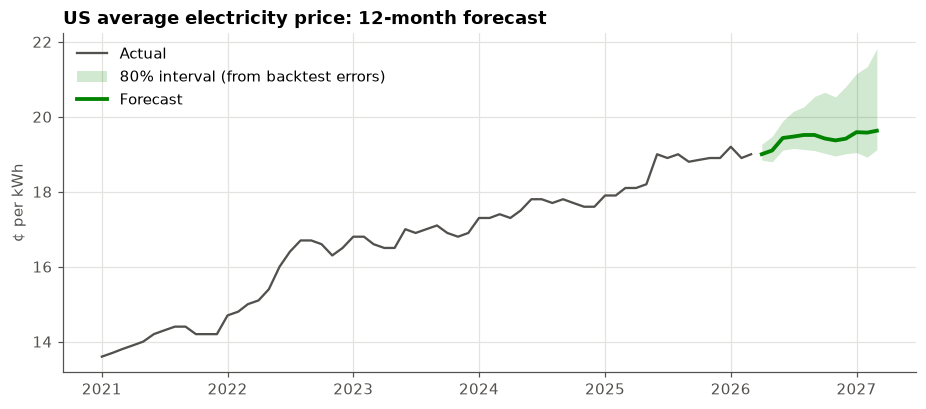

,forecast ¢,80% low ¢,80% high ¢
Apr 2026,19.00,18.84,19.27
May 2026,19.10,18.80,19.47
Jun 2026,19.43,19.11,19.89
Jul 2026,19.47,19.16,20.14
Aug 2026,19.51,19.13,20.26
Sep 2026,19.51,19.10,20.54
Oct 2026,19.42,19.02,20.65
Nov 2026,19.37,18.95,20.53
Dec 2026,19.42,19.01,20.81
Jan 2027,19.59,19.04,21.15


In [11]:
final = forecast_all(price, HORIZON)["Average (drift, ETS, SARIMA)"]
idx = pd.date_range(price.index[-1] + pd.DateOffset(months=1), periods=HORIZON, freq="MS")

avg_bt = bt[bt["model"] == "Average (drift, ETS, SARIMA)"].assign(ratio=lambda d: d["actual"] / d["forecast"])
q = avg_bt.groupby("h")["ratio"].quantile([0.1, 0.9]).unstack()

outlook = pd.DataFrame({"forecast ¢": final, "80% low ¢": final * q[0.1].values,
                        "80% high ¢": final * q[0.9].values}, index=idx)

fig, ax = plt.subplots(figsize=(10, 4))
recent = price["2021-01":]
ax.plot(recent, color=INK_2, lw=1.5, label="Actual")
ax.fill_between(idx, outlook["80% low ¢"], outlook["80% high ¢"], color=COLORS["Average (drift, ETS, SARIMA)"],
                alpha=0.18, lw=0, label="80% interval (from backtest errors)")
ax.plot(idx, outlook["forecast ¢"], color=COLORS["Average (drift, ETS, SARIMA)"], lw=2.5, label="Forecast")
ax.set(title="US average electricity price: 12-month forecast", ylabel="¢ per kWh")
ax.legend(loc="upper left")
plt.show()

outlook.index = outlook.index.strftime("%b %Y")
outlook

The forecast continues the recent upward trend, with seasonal bumps in the summer. The interval widens with the horizon and is skewed: the backtest's largest misses were under-forecasts during the surge, so the band reaches further above the forecast than below it.

## Revisiting the original capstone

This notebook revises the version I submitted for the D214 capstone (April 2026), which is kept unchanged in [`D214-capstone-electricity-price-forecast/`](../../D214-capstone-electricity-price-forecast/). The question and data are the same. What changed:

| Original | Revised | Why |
|---|---|---|
| Dropped the missing October 2025 row | Interpolated it | Dropping left a gap in a series the models treat as monthly, and it shifted the train/test split |
| One 30-month holdout; MAPE 0.77% | 25-origin rolling backtest, 1–12 month horizons | The single-window result depended on where the split fell (section 4) |
| SARIMA only | SARIMA vs. ETS vs. three baselines vs. an average | A model's error means little without a baseline to compare against |
| Hypothesis: "MAPE < 10%" | Compare models against baselines, by horizon | Even the naive forecast clears 10%, so that threshold couldn't tell good models from bad |
| `mean_absolute_percentage_error(forecast, actual)` | Arguments in the correct order | The function's signature is `(y_true, y_pred)` |
| Units given as "kw/H" | ¢/kWh | Correct units |
| Conclusion: recommend SARIMA | SARIMA only for 1–3 month forecasts; drift or an average beyond that | Supported by the backtest |

The original report and slides are in [`D214-capstone-electricity-price-forecast/reports/`](../../D214-capstone-electricity-price-forecast/reports/).

## Limitations and next steps

- **Univariate.** The models see only past prices. The surge was driven by fuel costs, mainly natural gas, which none of them can see. The obvious next step is to add Henry Hub natural gas prices (also on FRED) as an exogenous regressor (SARIMAX) and test whether they improve forecasts beyond three months.
- **A national average.** It hides large regional differences and isn't meant for comparing places. State-level EIA data would support regional models.
- **Short history.** Ten years gives 25 quarterly origins, and the error estimates are noisy, especially for the surge period. The FRED series goes back to 1978, so a longer history could be tested to see whether older regimes still help.
- **Intervals.** The empirical intervals come from only 25 errors per horizon. Conformal prediction or a longer backtest would make them more reliable.

## References

- Bensaidani, A., & Deveaux, P. (2026, February 10). *Electricity prices in the U.S.: a significant economic and electoral concern in the run-up to the midterms.* BNP Paribas Economic Research.
- Huntington, H., & Liddle, B. (2022). How energy prices shape OECD economic growth: Panel evidence from multiple decades. *Energy Economics, 111*, 106082. https://doi.org/10.1016/j.eneco.2022.106082
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.). OTexts. https://otexts.com/fpp3/ (chapters 5.2 on simple baselines, 5.10 on time-series cross-validation, 13.4 on forecast combinations)
- U.S. Bureau of Labor Statistics. *Average Price: Electricity per Kilowatt-Hour in U.S. City Average* [APU000072610]. Retrieved from FRED, Federal Reserve Bank of St. Louis, April 21, 2026. https://fred.stlouisfed.org/series/APU000072610
- U.S. Bureau of Labor Statistics. *CPI: Average Price Data.* https://www.bls.gov/cpi/factsheets/average-prices.htm